# Day 26 · Water — The water in the sky
### #30DayMapChallenge 2026 · ECMWF IFS 9 km open data · Map by Emma Pidduck

Most of the planet's fresh water is, at any instant, in the **air** — and it never sits still.
This is **total column water vapour**: how much water is stacked in the whole atmosphere above
each point, drawn on the globe as a single marble.

The bright ribbons threading out of the tropics are **atmospheric rivers** — narrow filaments
that can carry more water than the Amazon, and that feed (or flood) the mid-latitudes when they
make landfall. The dark subtropical zones either side of the equator are where the air descends,
dry — the same circulation that puts the world's great deserts where they are.

## Method

- One field, one instant: **`tcwv`** (total column water vapour, kg m⁻²) from the ECMWF IFS
  **9 km (0.1°)** open-data forecast, analysis step.
- Draw it on an **orthographic** projection — a true view of the sphere from space — centred on
  the Atlantic so both the ITCZ and a North-Atlantic atmospheric river read in one frame.
- `add_cyclic_point` closes the seam at the date line so the fill wraps seamlessly around the limb.
- Colour: a **deep-teal → white** ramp that is **monotonic in luminance** (verified below), so it
  reads for every colour-vision type and in greyscale, and keeps the house white background —
  no black space.

## Licence & attribution

**ECMWF Open Data** is published under **Creative Commons CC-BY-4.0**.

> © ECMWF · source www.ecmwf.int ·
> [Terms of use](https://apps.ecmwf.int/datasets/licences/general/).

By downloading from the open-data portal you agree to attribute ECMWF.

## Tools

| Tool | Role |
|---|---|
| [`ecmwf-opendata`](https://github.com/ecmwf/ecmwf-opendata) | retrieve the IFS 9 km `tcwv` field |
| [`earthkit-data`](https://earthkit-data.readthedocs.io) | read the GRIB into xarray |
| `cartopy` · `matplotlib` | orthographic globe, cyclic seam, render |

Nothing to configure — the open data needs no account.

In [1]:
# Run once if needed (uncomment):
#!pip install ecmwf-opendata earthkit-data cartopy matplotlib

In [2]:
import os, warnings
import numpy as np
import earthkit.data as ekd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgba
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
warnings.filterwarnings("ignore")

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]
BG, INK, MUT = "#ffffff", "#1d2733", "#6b7785"

### Configuration

The analysis (`step=0`) of the latest run — change `CLON`/`CLAT` to spin the globe to any face
(e.g. `CLON=140, CLAT=20` for the Pacific typhoon belt).

In [3]:
GRIB = "data/day26_tcwv.grib2"
CLON, CLAT = -40, 20          # orthographic centre: the Atlantic

## Retrieve — IFS 9 km `tcwv`

`resol="0p1"` is the gotcha that gets you the 9 km grid; the client defaults to 0.25°.

In [4]:
os.makedirs("data", exist_ok=True)
if not os.path.exists(GRIB):
    from ecmwf.opendata import Client
    Client().retrieve(type="fc", step=0, param="tcwv", resol="0p1", target=GRIB)

## Read & close the seam

In [5]:
ds = ekd.from_source("file", GRIB).to_xarray()
da = ds["tcwv"]
lat = da["latitude"].values
lon = da["longitude"].values
tcwv = da.values
# earthkit's xarray drops the time coord here — read the valid time straight from the GRIB
import xarray as xr
when = str(xr.open_dataset(GRIB, engine="cfgrib").valid_time.values)[:16].replace("T", " ") + " UTC"
vals, loncyc = add_cyclic_point(tcwv, coord=lon)
print(f"grid {tcwv.shape}   tcwv {tcwv.min():.1f} to {tcwv.max():.1f} kg/m²   {when}")

grid (1801, 3600)   tcwv 0.2 to 82.4 kg/m²   2026-10-29 00:00 UTC


### Colour — deep teal → white, colourblind-safe

Dry air sits dark teal-navy; saturated tropical air goes to white. The ramp is **monotonic in
luminance**, so brightness alone encodes the value — it survives every form of colour-vision
deficiency and a greyscale print.

In [6]:
CMAP = LinearSegmentedColormap.from_list("vapour", [
    "#0b2a3a", "#14455c", "#1f6f86", "#2fa0ab", "#67c6c0", "#aee3dc", "#e8f7f3", "#ffffff"])
rgb = np.array([to_rgba(CMAP(t))[:3] for t in np.linspace(0, 1, 256)])
lum = 0.2126*rgb[:,0] + 0.7152*rgb[:,1] + 0.0722*rgb[:,2]
mono = (np.diff(lum) >= -1e-3).all() or (np.diff(lum) <= 1e-3).all()
print("vapour ramp luminance-monotonic:", bool(mono), f"({lum[0]:.2f} -> {lum[-1]:.2f})")

vapour ramp luminance-monotonic: True (0.14 -> 1.00)


## Render

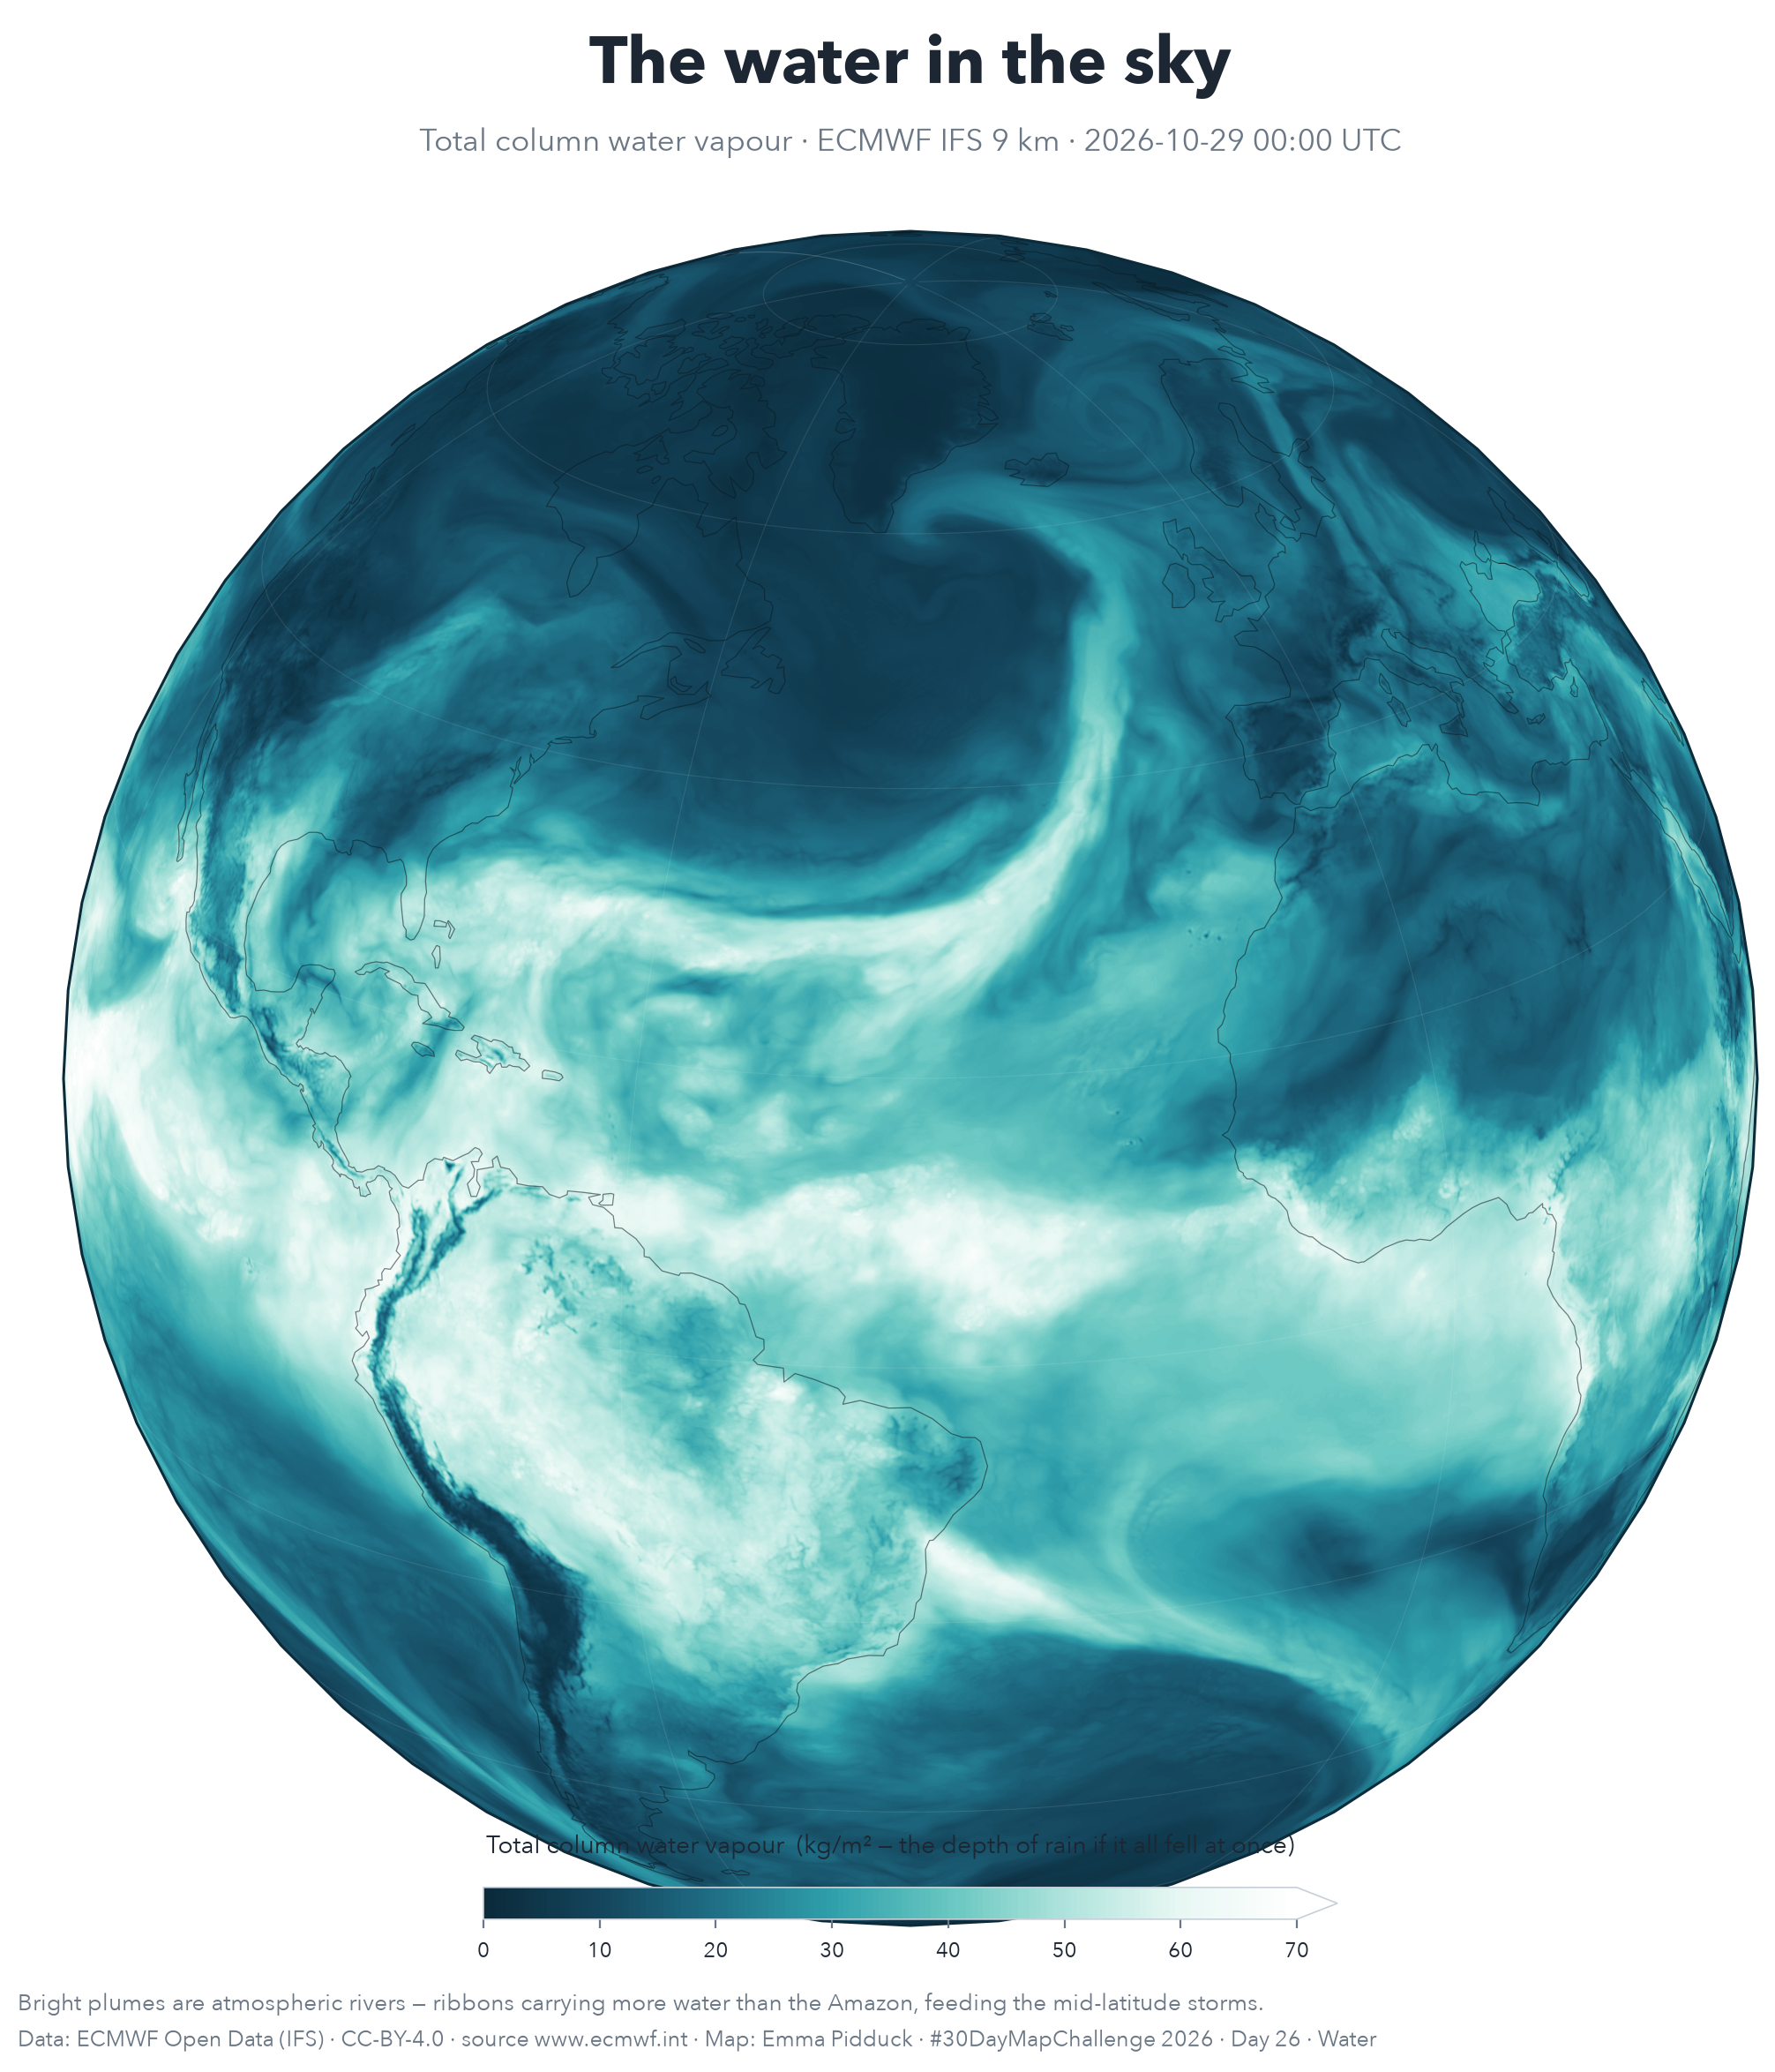

In [7]:
proj = ccrs.Orthographic(central_longitude=CLON, central_latitude=CLAT)
tp = dict(transform=ccrs.PlateCarree())

fig = plt.figure(figsize=(11, 12), dpi=200); fig.patch.set_facecolor(BG)
ax = fig.add_axes([0.04, 0.085, 0.92, 0.80], projection=proj)
ax.patch.set_alpha(0); ax.set_global()

# soft halo for depth — no hard black edge, keeps the white background
for r, a in zip(np.linspace(1.015, 1.11, 30), np.linspace(0.14, 0.0, 30)):
    ax.add_patch(plt.Circle((0.5, 0.5), 0.5*r, transform=ax.transAxes,
                            color="#2fa0ab", alpha=a, zorder=0, lw=0))

cf = ax.contourf(loncyc, lat, vals, levels=np.linspace(0, 70, 141),
                 cmap=CMAP, extend="max", zorder=1, **tp)
ax.gridlines(color="#ffffff", alpha=0.10, linewidth=0.4, zorder=3)
ax.add_feature(cfeature.COASTLINE.with_scale("110m"), edgecolor="#0b1a22",
               linewidth=0.45, alpha=0.55, zorder=4)
ax.spines["geo"].set_edgecolor("#0b2a3a"); ax.spines["geo"].set_linewidth(1.1)

cax = fig.add_axes([0.28, 0.088, 0.44, 0.015])
cb = fig.colorbar(cf, cax=cax, orientation="horizontal", extend="max",
                  ticks=[0,10,20,30,40,50,60,70])
cb.set_label("Total column water vapour  (kg/m² — the depth of rain if it all fell at once)",
             color=INK, fontsize=10, labelpad=14)
cb.ax.xaxis.set_label_position("top")
cb.ax.xaxis.set_tick_params(color=MUT, labelsize=8.5)
plt.setp(plt.getp(cb.ax, "xticklabels"), color=INK)
cb.outline.set_edgecolor("#c7d0d8"); cb.outline.set_linewidth(0.6)

fig.text(0.5, 0.955, "The water in the sky", ha="center", color=INK, fontsize=27, fontweight="bold")
fig.text(0.5, 0.923, f"Total column water vapour · ECMWF IFS 9 km · {when}",
         ha="center", color=MUT, fontsize=12.5)
fig.text(0.04, 0.045, "Bright plumes are atmospheric rivers — ribbons carrying more water than the Amazon, feeding the mid-latitude storms.",
         color=MUT, fontsize=9.3)
fig.text(0.04, 0.028, "Data: ECMWF Open Data (IFS) · CC-BY-4.0 · source www.ecmwf.int · Map: Emma Pidduck · #30DayMapChallenge 2026 · Day 26 · Water",
         color=MUT, fontsize=9)
fig.savefig("day26_water_vapour.png", facecolor=BG, bbox_inches="tight")
plt.show()

## Note

The deep plume curling out of the Caribbean and the Gulf, up the US eastern seaboard and
spiralling into a North-Atlantic low, is a textbook **atmospheric river** — the "tropical
moisture conveyor" that can dump a month of rain on western Europe in a day. The sharp bright
band straddling the equator is the **Intertropical Convergence Zone**; the dark voids over the
Sahara and the subtropical South Atlantic are the descending, drying branches of the same
Hadley circulation.

**Saved:** `day26_water_vapour.png` — ready to post.

*Day 2 Lines · Day 6 Vintage · Day 20 Hexagons · Day 22 Projections · Day 28 Feeling.*